# 03 Error analysis by device type and condition

Which device types and conditions produce the misclassifications? Based on the exported
predictions of the three class random forest (no training).

1. Per device type and group: where do its packets go (background, own group, other group)?
2. The same per address (majority vote): how many addresses of each device are found?
3. Background addresses that are predicted as a group (false positives) by manufacturer.
4. Errors over time (two hour blocks in domain, 10 minute windows on the university capture).

In [1]:
import sys, pathlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append(str(pathlib.Path.cwd()))  # the notebooks live in code/analysis
import analysis_utils as au
importlib.reload(au)

RESULTS = pathlib.Path('results')
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

EXPS = au.available_experiments()
print('experiments with exported artifacts:', EXPS)
missing = [e for e in au.EXPERIMENTS if e not in EXPS]
if missing:
    print('NOT YET RERUN (no artifacts):', missing)

experiments with exported artifacts: ['E1_apple_same', 'E2_apple_diff', 'E3_samsung_same', 'E4_samsung_diff', 'E5_mixed_same', 'E6_mixed_diff']


In [2]:
MODEL = 'random_forest'
SPLIT = 'grouped'
LABEL = 'multi'

## 1. Packet outcome per device type and group

In [3]:
rows = []
for e in EXPS:
    for frame in ['indomain', 'transfer']:
        p = au.load_predictions(e, LABEL, MODEL, SPLIT, frame)
        tgt = p[p['y_true'] != 0]
        for (dev, grp), g in tgt.groupby(['labelled_device', 'y_true']):
            rows.append(dict(exp=au.exp_name(e), frame=frame, device=dev, group=int(grp),
                             packets=len(g), sources=g['source'].nunique(),
                             own_group=(g['y_pred'] == grp).mean(),
                             other_group=((g['y_pred'] != grp) & (g['y_pred'] != 0)).mean(),
                             background=(g['y_pred'] == 0).mean()))
dev = pd.DataFrame(rows)
dev.to_csv(RESULTS / 'error_by_device.csv', index=False)
dev[dev['frame'] == 'transfer'].round(3)

,exp,frame,device,group,packets,sources,own_group,other_group,background
6,E1 apple same,transfer,Buds,1,10000,10,0.900,0.000,0.100
7,E1 apple same,transfer,Buds,2,13994,19,0.000,0.643,0.357
8,E1 apple same,transfer,Phone,1,9000,9,1.000,0.000,0.000
9,E1 apple same,transfer,Phone,2,8257,9,0.000,1.000,0.000
10,E1 apple same,transfer,Smart Tag,1,5862,19,0.044,0.005,0.950
11,E1 apple same,transfer,Smart Tag,2,5872,19,0.001,0.005,0.995
18,E2 apple diff,transfer,Buds,1,8000,8,0.011,0.864,0.125
19,E2 apple diff,transfer,Buds,2,8000,8,0.875,0.000,0.125
20,E2 apple diff,transfer,Phone,1,7000,7,0.981,0.000,0.019
21,E2 apple diff,transfer,Phone,2,6000,6,0.321,0.679,0.001


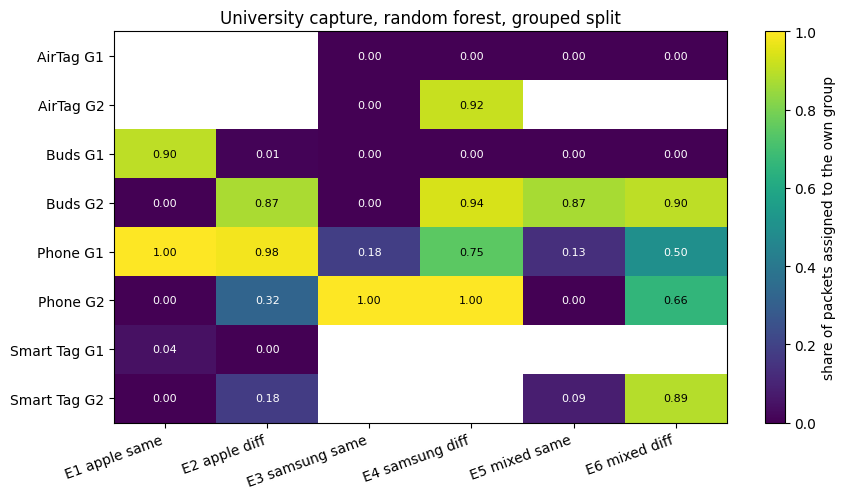

In [4]:
# Recall of the own group per device type on the university capture
h = (dev[dev['frame'] == 'transfer'].assign(unit=lambda d: d['device'] + ' G' + d['group'].astype(str))
     .pivot(index='unit', columns='exp', values='own_group'))
fig, ax = plt.subplots(figsize=(9, 0.45 * len(h) + 1.5))
im = ax.imshow(h.values, cmap='viridis', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns, rotation=20, ha='right')
ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        if not np.isnan(h.values[i, j]):
            ax.text(j, i, f'{h.values[i, j]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if h.values[i, j] < 0.5 else 'black')
fig.colorbar(im, label='share of packets assigned to the own group')
ax.set_title('University capture, random forest, grouped split')
plt.tight_layout(); plt.savefig(FIGURES / 'fig_error_by_device_transfer.pdf'); plt.show()

## 1b. The same per sublabel (e.g. phone scan requests against adverts)

In [5]:
rows = []
for e in EXPS:
    p = au.load_predictions(e, LABEL, MODEL, SPLIT, 'transfer')
    tgt = p[p['y_true'] != 0].copy()
    tgt['sublabel_device'] = tgt['sublabel_device'].fillna('(none)')
    for (dev_, sub, grp), g in tgt.groupby(['labelled_device', 'sublabel_device', 'y_true']):
        rows.append(dict(exp=au.exp_name(e), device=dev_, sublabel=sub, group=int(grp), packets=len(g),
                         own_group=(g['y_pred'] == grp).mean(),
                         other_group=((g['y_pred'] != grp) & (g['y_pred'] != 0)).mean(),
                         background=(g['y_pred'] == 0).mean()))
pd.DataFrame(rows).round(3)

,exp,device,sublabel,group,packets,own_group,other_group,background
0,E1 apple same,Buds,Buds,1,10000,0.900,0.000,0.100
1,E1 apple same,Buds,Buds,2,13994,0.000,0.643,0.357
2,E1 apple same,Phone,Phone Scan,1,9000,1.000,0.000,0.000
3,E1 apple same,Phone,Phone Scan,2,8257,0.000,1.000,0.000
4,E1 apple same,Smart Tag,Smart Tag,1,5862,0.044,0.005,0.950
5,E1 apple same,Smart Tag,Smart Tag,2,5872,0.001,0.005,0.995
6,E2 apple diff,Buds,Buds,1,8000,0.011,0.864,0.125
7,E2 apple diff,Buds,Buds,2,8000,0.875,0.000,0.125
8,E2 apple diff,Phone,Phone Scan,1,7000,0.981,0.000,0.019
9,E2 apple diff,Phone,Phone Scan,2,6000,0.321,0.679,0.001


## 2. Per address (majority vote)

In [6]:
rows = []
for e in EXPS:
    for frame in ['indomain', 'transfer']:
        p = au.load_predictions(e, LABEL, MODEL, SPLIT, frame)
        src = au.majority_vote(p, p['y_true'], p['y_pred'])
        for (d_, grp), g in src[src['y_true'] != 0].groupby(['labelled_device', 'y_true']):
            rows.append(dict(exp=au.exp_name(e), frame=frame, device=d_, group=int(grp), addresses=len(g),
                             correct=(g['y_pred'] == grp).sum(),
                             other_group=((g['y_pred'] != grp) & (g['y_pred'] != 0)).sum(),
                             background=(g['y_pred'] == 0).sum(),
                             median_packets_per_address=g['n_packets'].median()))
src_dev = pd.DataFrame(rows)
src_dev.to_csv(RESULTS / 'error_by_device_sources.csv', index=False)
src_dev[src_dev['frame'] == 'transfer']

,exp,frame,device,group,addresses,correct,other_group,background,median_packets_per_address
6,E1 apple same,transfer,Buds,1,10,9,0,1,1000.0
7,E1 apple same,transfer,Buds,2,19,0,9,10,664.0
8,E1 apple same,transfer,Phone,1,9,9,0,0,1000.0
9,E1 apple same,transfer,Phone,2,9,0,9,0,1000.0
10,E1 apple same,transfer,Smart Tag,1,19,2,0,17,297.0
11,E1 apple same,transfer,Smart Tag,2,19,0,2,17,270.0
18,E2 apple diff,transfer,Buds,1,8,0,7,1,1000.0
19,E2 apple diff,transfer,Buds,2,8,7,0,1,1000.0
20,E2 apple diff,transfer,Phone,1,7,7,0,0,1000.0
21,E2 apple diff,transfer,Phone,2,6,2,4,0,1000.0


## 3. False positives: background addresses predicted as a group

In [7]:
rows = []
for e in EXPS:
    p = au.load_predictions(e, LABEL, MODEL, SPLIT, 'transfer')
    ev = au.load_frame(e, 'eval', columns=['company_id'])
    p['company_id'] = ev['company_id'].to_numpy()[p['row']]
    bg = p[p['y_true'] == 0]
    fp = bg[bg['y_pred'] != 0]
    by = (fp.groupby('company_id', dropna=False)
          .agg(fp_packets=('y_pred', 'size'), fp_sources=('source', 'nunique'),
               as_g1=('y_pred', lambda s: (s == 1).sum()), as_g2=('y_pred', lambda s: (s == 2).sum()))
          .sort_values('fp_packets', ascending=False).head(10).reset_index())
    by.insert(0, 'exp', au.exp_name(e))
    by['share_of_all_fp'] = by['fp_packets'] / max(len(fp), 1)
    by['bg_fp_rate'] = len(fp) / max(len(bg), 1)
    rows.append(by)
fps = pd.concat(rows, ignore_index=True)
fps.to_csv(RESULTS / 'false_positives_by_company.csv', index=False)
fps

,exp,company_id,fp_packets,fp_sources,as_g1,as_g2,share_of_all_fp,bg_fp_rate
0,E1 apple same,"Apple, Inc.",113153,293,76855,36298,0.661396,0.133902
1,E1 apple same,Undefined,49450,478,16158,33292,0.289043,0.133902
2,E1 apple same,Samsung Electronics Co. Ltd.,1841,3,1657,184,0.010761,0.133902
3,E1 apple same,Xiaomi Inc.,1650,14,1642,8,0.009644,0.133902
4,E1 apple same,Unknown,1510,203,1076,434,0.008826,0.133902
5,E1 apple same,Sony Corporation,1214,6,1139,75,0.007096,0.133902
6,E1 apple same,Microsoft,938,59,937,1,0.005483,0.133902
7,E1 apple same,Avago Technologies,100,69,80,20,0.000585,0.133902
8,E1 apple same,ORSO Inc.,95,67,76,19,0.000555,0.133902
9,E1 apple same,"Staccato Communications, Inc.",89,59,67,22,0.000520,0.133902


## 4. Errors over time

In [8]:
rows = []
for e in EXPS:
    p = au.load_predictions(e, LABEL, MODEL, SPLIT, 'indomain')
    for b, g in p.groupby('block'):
        t = g[g['y_true'] != 0]
        rows.append(dict(exp=au.exp_name(e), frame='indomain', window=f'block {int(b)}',
                         target_packets=len(t), own_group=(t['y_pred'] == t['y_true']).mean() if len(t) else np.nan))
    p = au.load_predictions(e, LABEL, MODEL, SPLIT, 'transfer')
    p['window'] = ((p['time'] - p['time'].min()) // 600).astype(int)
    for w, g in p.groupby('window'):
        t = g[g['y_true'] != 0]
        rows.append(dict(exp=au.exp_name(e), frame='transfer', window=f'{10 * w:03d}-{10 * w + 10:03d} min',
                         target_packets=len(t), own_group=(t['y_pred'] == t['y_true']).mean() if len(t) else np.nan))
over_time = pd.DataFrame(rows)
over_time.to_csv(RESULTS / 'error_over_time.csv', index=False)
over_time.pivot_table(index=['frame', 'window'], columns='exp', values='own_group').round(2)

exp                   E1 apple same  E2 apple diff  E3 samsung same  \
frame    window                                                       
indomain block 0               0.90           0.81             0.96   
         block 1               0.94           0.85             0.97   
         block 2               0.88           0.90             0.93   
         block 3               0.83           0.75             0.96   
         block 4               0.79           0.93             0.98   
transfer 000-010 min           0.36           0.62             0.41   
         010-020 min           0.37           0.56             0.44   
         020-030 min           0.33           0.38             0.46   
         030-040 min           0.32           0.36             0.44   
         040-050 min           0.34           0.36             0.32   
         050-060 min           0.33           0.37             0.32   
         060-070 min           0.35           0.41             0.30   
         070-080 min           0.33           0.40             0.30   
         080-090 min           0.39           0.54             0.20   
         090-100 min           0.31            NaN             0.22   
         100-110 min           0.30            NaN             0.25   
         110-120 min           0.38            NaN             0.23   
         120-130 min           0.38            NaN             0.14   

exp                   E4 samsung diff  E5 mixed same  E6 mixed diff  
frame    window                                                      
indomain block 0                 1.00           0.97           0.97  
         block 1                 1.00           0.97           0.98  
         block 2                 1.00           0.99           0.98  
         block 3                 1.00            NaN            NaN  
         block 4                 1.00            NaN            NaN  
transfer 000-010 min             0.81           0.22           0.65  
         010-020 min             0.77           0.23           0.60  
         020-030 min             0.79           0.28           0.59  
         030-040 min             0.79           0.19           0.61  
         040-050 min             0.76           0.28           0.61  
         050-060 min             0.75           0.21           0.59  
         060-070 min             0.79           0.21           0.60  
         070-080 min             0.75           0.21           0.63  
         080-090 min             0.74           0.17           0.61  
         090-100 min             0.73            NaN           0.62  
         100-110 min             0.80            NaN           0.61  
         110-120 min              NaN            NaN           0.59  
         120-130 min              NaN            NaN           0.40